#Section I - Dataset Definition and Exploratory Data Analysis (EDA)

## Dataset Definition

**Dataset:** London Smart Meters

**Data source:** London Smart Meters dataset, loaded from Google Drive.

**Dataset description:** The dataset contains electricity consumption measurements from 5,560 households in London, UK. Each household has an individual time series of electricity consumption recorded at 30-minute intervals.

**Current forecasting target:** Electricity consumption (`consumption_kwh`) for household T1.

**Target unit:** Kilowatt-hours (kWh) per 30-minute interval.

**Native frequency:** 30 minutes.

**Resampling:** EDA uses the native 30-minute data. For modelling, the 30-minute readings are summed to hourly consumption (kWh per hour) in Section II.

**Dataset coverage:** November 24, 2011 – February 27, 2014.

**Selected series coverage (T1):** October 13, 2012 – February 22, 2014.

**Missingness:** The initial dataset audit identified no missing consumption observations across the 5,560 household series.

**Duplicates:** Household identifiers were checked for duplicates. The selected series contains unique timestamps after reconstruction.

**Timestamp gaps:** Timestamps are reconstructed using each household's start timestamp and the dataset's stated 30-minute frequency. The selected series contains no missing observations; however, timestamp continuity is assumed from the dataset structure rather than independently verified against original observation timestamps.

### Planned Forecasting Configuration

The following settings will be used for Stage 1 modelling:

- **Scope:** Household T1 for initial implementation. Aggregation to mean consumption per active household will be considered for the final dataset configuration.
- **Frequency:** Hourly, aggregated from the original 30-minute observations.
- **Lookback:** Previous 168 hours (7 days).
- **Forecast horizon:** Next 24 hours.
- **Data split:** Chronological 60% training, 20% validation, and 20% testing.
- **Preprocessing:** Fit scalers and imputers using training data only.
- **Evaluation metrics:** MAE, RMSE, sMAPE or MASE, and percentage improvement over the best traditional baseline.
- **Model consistency:** All models will use the same input windows, forecast horizon, loss function, evaluation metrics, random seed, and test instances.

### Exploratory Data Analysis

The exploratory analysis examines short-term electricity consumption patterns, daily seasonality, and differences in recording duration across households. These visualizations help characterize the dataset before preprocessing and model development.

In [1]:
# Import libraries for data manipulation
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Set graph style
sns.set_theme(style="whitegrid")

# Display all columns when inspecting datasets
pd.set_option("display.max_columns", None)

In [2]:
import os
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/london_smart_meters_dataset_without_missing_values.tsf'
file_name = os.path.basename(file_path)
print(file_name)

Mounted at /content/drive
london_smart_meters_dataset_without_missing_values.tsf


In [3]:
import pandas as pd
import numpy as np

def convert_tsf_to_dataframe(file_path):

    # Lists to store the data
    attributes = []
    data = []

    # Track where the actual time-series data begins
    data_started = False

    with open(file_path, "r", encoding="cp1252") as file:

        for line in file:

            line = line.strip()

            # Skip empty lines
            if not line:
                continue

            # Read attribute names from metadata
            if line.startswith("@attribute"):
                attributes.append(line.split()[1])

            # Identify beginning of data
            elif line.startswith("@data"):
                data_started = True

            # Read time-series observations
            elif data_started:

                # Separate metadata fields from observations
                values = line.split(":", len(attributes))

                # Extract metadata
                metadata = values[:-1]

                # Convert observations into numeric values
                series = [
                    float(x) if x != "?" else np.nan
                    for x in values[-1].split(",")
                ]

                data.append(metadata + [series])

    # Create DataFrame
    df = pd.DataFrame(
        data,
        columns=attributes + ["series_value"]
    )

    return df

In [4]:
# Convert TSF file into a DataFrame using the defined file_path variable
df = convert_tsf_to_dataframe(file_path)

# Display first five rows
display(df.head())

# Check dimensions
print("Number of time series:", df.shape[0])
print("Number of columns:", df.shape[1])

# Check column names
print("Columns:", df.columns.tolist())

,series_name,start_timestamp,series_value
0,T1,2012-10-13 00-00-01,"[0.263, 0.269, 0.275, 0.256, 0.211, 0.136, 0.1..."
1,T2,2011-12-04 00-00-01,"[0.175, 0.098, 0.144, 0.065, 0.071, 0.037, 0.0..."
2,T3,2012-03-23 00-00-01,"[1.337, 1.426, 0.996, 0.971, 0.994, 0.952, 0.8..."
3,T4,2012-05-09 00-00-01,"[0.18, 0.086, 0.106, 0.173, 0.146, 0.223, 0.21..."
4,T5,2012-09-18 00-00-01,"[0.076, 0.079, 0.123, 0.109, 0.051, 0.069, 0.0..."


Number of time series: 5560
Number of columns: 3
Columns: ['series_name', 'start_timestamp', 'series_value']


In [5]:
# Display dataset information
df.info()

# Show the first time series
print("First time series:")
print(df["series_value"].iloc[0][:10])

# Check lengths of individual time series
df["series_length"] = df["series_value"].apply(len)

print("\nTime series length statistics:")
display(df["series_length"].describe())

# Check missing values inside the time series
df["missing_count"] = df["series_value"].apply(
    lambda x: np.isnan(x).sum()
)

print("\nTotal missing observations:")
print(df["missing_count"].sum())

print("\nNumber of series containing missing observations:")
print((df["missing_count"] > 0).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5560 entries, 0 to 5559
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   series_name      5560 non-null   object
 1   start_timestamp  5560 non-null   object
 2   series_value     5560 non-null   object
dtypes: object(3)
memory usage: 130.4+ KB
First time series:
[0.263, 0.269, 0.275, 0.256, 0.211, 0.136, 0.161, 0.119, 0.167, 0.109]

Time series length statistics:


,series_length
count,5560.000000
mean,29951.240288
std,5263.464530
min,288.000000
25%,28512.000000
50%,30864.000000
75%,32496.000000
max,39648.000000



Total missing observations:
0

Number of series containing missing observations:
0


In [6]:
# Convert start timestamps into datetime format
df["start_timestamp"] = pd.to_datetime(
    df["start_timestamp"],
    format="%Y-%m-%d %H-%M-%S"
)

# Check the converted timestamps
print("Earliest start date:", df["start_timestamp"].min())
print("Latest start date:", df["start_timestamp"].max())

# Check that the conversion worked
print("\nData types:")
print(df.dtypes)

Earliest start date: 2011-11-24 00:00:01
Latest start date: 2013-10-31 00:00:01

Data types:
series_name                object
start_timestamp    datetime64[ns]
series_value               object
series_length               int64
missing_count               int64
dtype: object


In [7]:
# Define the sampling frequency
frequency = pd.Timedelta(minutes=30)

# Calculate the ending timestamp for each meter
df["end_timestamp"] = (
    df["start_timestamp"]
    + (df["series_length"] - 1) * frequency
)

# Calculate the duration of each time series
df["duration_days"] = (
    df["end_timestamp"] - df["start_timestamp"]
).dt.total_seconds() / (60 * 60 * 24)

# Display time coverage statistics
print("Overall dataset start:", df["start_timestamp"].min())
print("Overall dataset end:", df["end_timestamp"].max())

print("\nDuration statistics (days):")
display(df["duration_days"].describe())

# Display first five meters
display(
    df[
        ["series_name", "start_timestamp",
         "end_timestamp", "duration_days"]
    ].head()
)

Overall dataset start: 2011-11-24 00:00:01
Overall dataset end: 2014-02-27 23:30:01

Duration statistics (days):


,duration_days
count,5560.000000
mean,623.963339
std,109.655511
min,5.979167
25%,593.979167
50%,642.979167
75%,676.979167
max,825.979167


,series_name,start_timestamp,end_timestamp,duration_days
0,T1,2012-10-13 00:00:01,2014-02-22 23:30:01,497.979167
1,T2,2011-12-04 00:00:01,2014-02-24 23:30:01,813.979167
2,T3,2012-03-23 00:00:01,2013-05-06 23:30:01,409.979167
3,T4,2012-05-09 00:00:01,2012-12-16 23:30:01,221.979167
4,T5,2012-09-18 00:00:01,2014-02-25 23:30:01,525.979167


In [8]:


# Check for duplicate meter identifiers
duplicate_meters = df["series_name"].duplicated().sum()

print("Duplicate meter identifiers:", duplicate_meters)

# Check for missing metadata
print("\nMissing metadata:")
print(df[["series_name", "start_timestamp"]].isnull().sum())

# Check for negative electricity consumption values
negative_counts = df["series_value"].apply(
    lambda x: np.sum(np.array(x) < 0)
)

print("\nTotal negative readings:", negative_counts.sum())

# Check for zero electricity consumption values
zero_counts = df["series_value"].apply(
    lambda x: np.sum(np.array(x) == 0)
)

print("Total zero readings:", zero_counts.sum())

# Calculate total observations
total_observations = df["series_length"].sum()

print("\nTotal observations:", total_observations)

Duplicate meter identifiers: 0

Missing metadata:
series_name        0
start_timestamp    0
dtype: int64

Total negative readings: 0
Total zero readings: 1986689

Total observations: 166528896


In [9]:
# Calculate summary statistics for each meter
df["mean_consumption"] = df["series_value"].apply(np.mean)
df["std_consumption"] = df["series_value"].apply(np.std)
df["max_consumption"] = df["series_value"].apply(np.max)
df["min_consumption"] = df["series_value"].apply(np.min)

# Display summary statistics across all meters
display(
    df[
        ["mean_consumption", "std_consumption",
         "min_consumption", "max_consumption"]
    ].describe().round(3)
)

,mean_consumption,std_consumption,min_consumption,max_consumption
count,5560.000,5560.000,5560.000,5560.000
mean,0.213,0.211,0.022,2.351
std,0.156,0.146,0.029,1.162
min,0.000,0.000,0.000,0.000
25%,0.112,0.114,0.001,1.535
50%,0.174,0.176,0.014,2.114
75%,0.268,0.264,0.030,2.916
max,2.112,2.027,0.610,10.761


In [10]:
# Identify candidate meters with at least 600 days of data
candidates = df[df["duration_days"] >= 600].copy()

# Calculate typical electricity consumption
median_consumption = candidates["mean_consumption"].median()

# Rank meters by distance from typical consumption
candidates["distance_from_median"] = abs(
    candidates["mean_consumption"] - median_consumption
)

# Display the 10 most representative candidates
display(
    candidates.sort_values("distance_from_median")[
        ["series_name", "duration_days",
         "mean_consumption", "std_consumption"]
    ].head(10)
)

,series_name,duration_days,mean_consumption,std_consumption
4858,T4859,674.979167,0.168973,0.181195
405,T406,663.979167,0.168987,0.164734
5329,T5330,625.979167,0.168951,0.214893
4015,T4016,655.979167,0.168995,0.146066
3065,T3066,657.979167,0.168923,0.193008
2685,T2686,661.979167,0.169085,0.126244
2278,T2279,644.979167,0.168838,0.235772
5497,T5498,717.979167,0.168832,0.234748
1693,T1694,766.979167,0.169187,0.266793
3591,T3592,712.979167,0.169269,0.146183


In [11]:
# Select the meter agreed upon by the group
selected_meter = "T1"  # Temporary until final selection

meter = df.loc[
    df["series_name"] == selected_meter
].iloc[0]

# Create timestamps for the meter
timestamps = pd.date_range(
    start=meter["start_timestamp"],
    periods=len(meter["series_value"]),
    freq="30min"
)

# Create a time-series DataFrame
meter_df = pd.DataFrame({
    "timestamp": timestamps,
    "consumption_kwh": meter["series_value"]
})

# Set timestamp as index
meter_df = meter_df.set_index("timestamp")

# Display first five observations
display(meter_df.head())

,consumption_kwh
timestamp,
2012-10-13 00:00:01,0.263
2012-10-13 00:30:01,0.269
2012-10-13 01:00:01,0.275
2012-10-13 01:30:01,0.256
2012-10-13 02:00:01,0.211


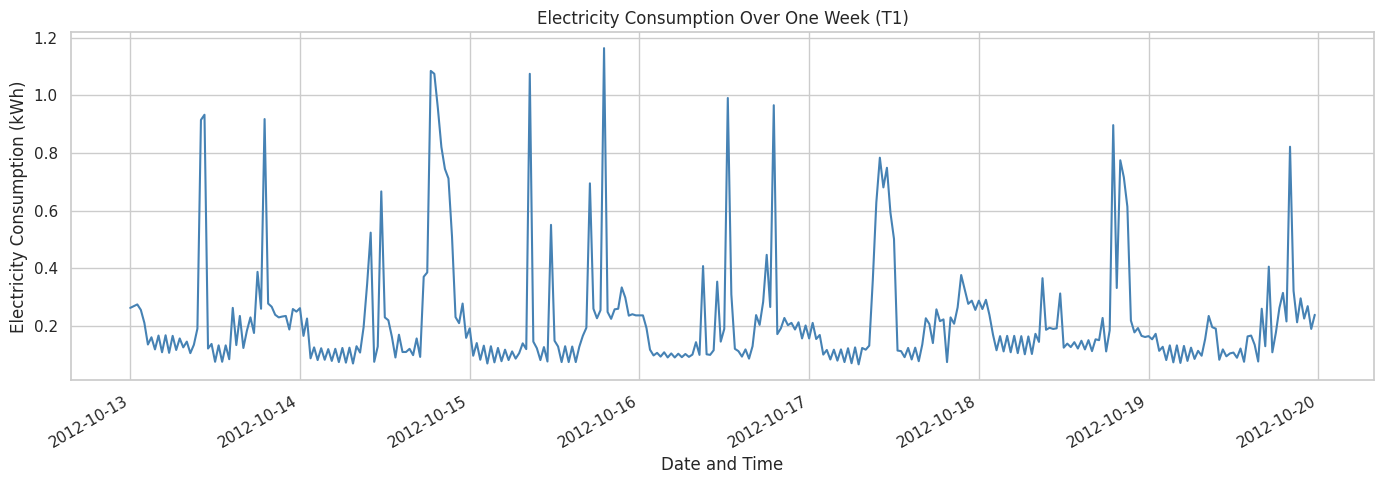

In [12]:
# Plot electricity consumption for the first 7 days
plt.figure(figsize=(14, 5))

meter_df["consumption_kwh"].iloc[:336].plot(
    color="steelblue"
)

plt.title(f"Electricity Consumption Over One Week ({selected_meter})")
plt.xlabel("Date and Time")
plt.ylabel("Electricity Consumption (kWh)")

plt.grid(True)
plt.tight_layout()
plt.show()

The graph illustrates electricity consumption for Meter T1 over a seven-day period, from October 13 to October 20, 2012. Consumption fluctuates considerably throughout the week, with several sharp peaks reaching approximately 1.16 kWh per 30-minute interval. Between these peaks, consumption generally remains between 0.1 and 0.3 kWh. These fluctuations suggest periods of relatively consistent baseline electricity usage interrupted by short periods of significantly higher demand. This variability is important for forecasting, as models must account for both regular consumption patterns and sudden increases in electricity demand.

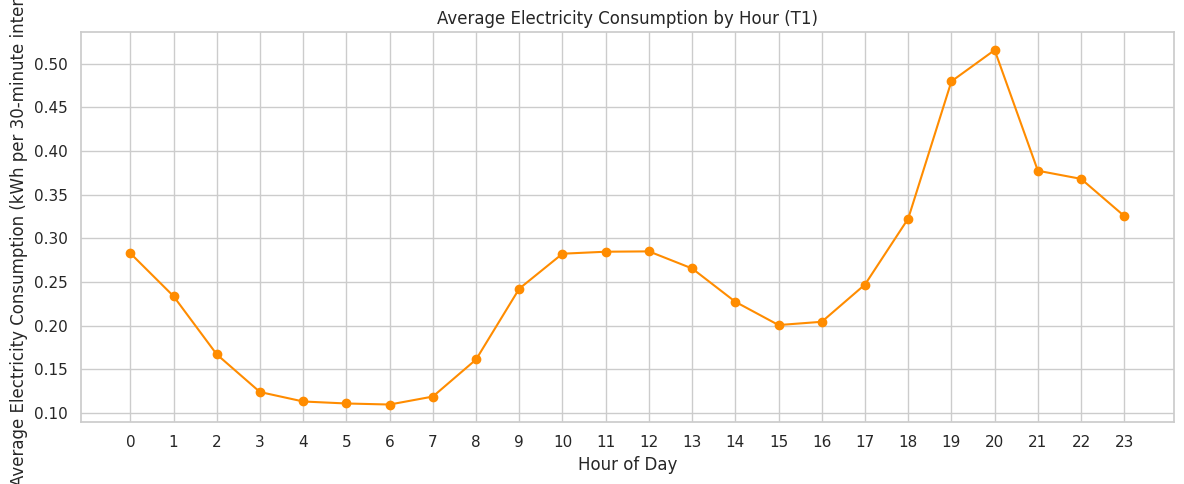

In [13]:
# Create an hour-of-day column
meter_df["hour"] = meter_df.index.hour

# Calculate average consumption for each hour
hourly_average = meter_df.groupby("hour")["consumption_kwh"].mean()

# Plot average consumption by hour
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_average.index,
    hourly_average.values,
    marker="o",
    color="darkorange"
)

plt.title(f"Average Electricity Consumption by Hour ({selected_meter})")
plt.xlabel("Hour of Day")
plt.ylabel("Average Electricity Consumption (kWh per 30-minute interval)")

plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

The graph demonstrates a clear relationship between electricity consumption and the time of day. Consumption is lowest during the early morning, particularly between 3:00 AM and 6:00 AM, averaging approximately 0.11 kWh per 30-minute interval. Demand gradually increases throughout the morning before reaching its highest levels in the evening, with a peak of approximately 0.51 kWh around 8:00 PM. This pattern suggests that electricity consumption follows a daily cycle, potentially influenced by household occupancy and activities. These recurring patterns indicate that historical consumption and time-of-day information may be useful features for forecasting future electricity demand.

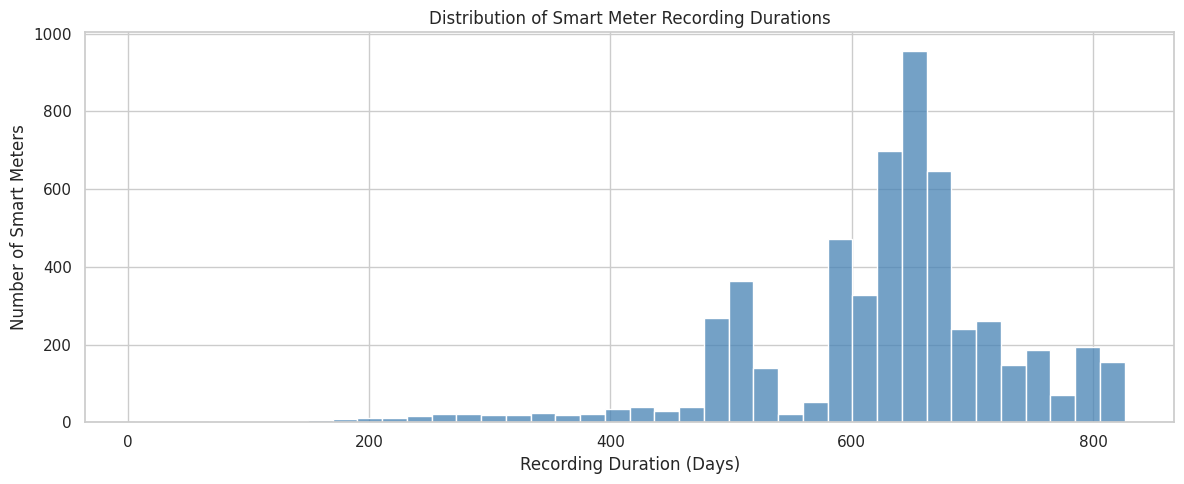

In [14]:
plt.figure(figsize=(12, 5))

sns.histplot(
    df["duration_days"],
    bins=40,
    color="steelblue"
)

plt.title("Distribution of Smart Meter Recording Durations")
plt.xlabel("Recording Duration (Days)")
plt.ylabel("Number of Smart Meters")

plt.tight_layout()
plt.show()

The histogram illustrates the variation in recording durations across the 5,560 smart meters. Most meters have recording periods concentrated between approximately 600 and 700 days, with the highest frequency occurring around 650 to 670 days. However, the dataset also contains shorter recording periods, with durations ranging from approximately 6 to 826 days. This variation indicates that the smart meters do not all cover the same time period. When preparing data for forecasting, differences in recording duration must be considered to ensure that sufficient historical observations are available and that the selected time series is suitable for model training and evaluation.

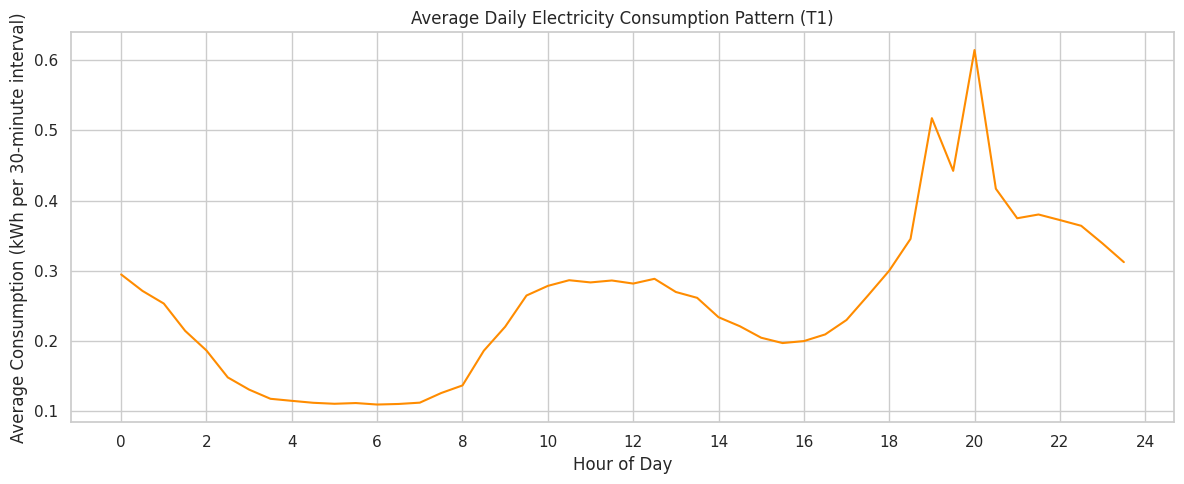

In [15]:
# Create half-hour time-of-day intervals
meter_df["time_of_day"] = (
    meter_df.index.hour * 2
    + meter_df.index.minute // 30
)

# Average consumption for each interval
daily_pattern = meter_df.groupby(
    "time_of_day"
)["consumption_kwh"].mean()

plt.figure(figsize=(12, 5))

plt.plot(
    daily_pattern.index / 2,
    daily_pattern.values,
    color="darkorange"
)

plt.title(f"Average Daily Electricity Consumption Pattern ({selected_meter})")
plt.xlabel("Hour of Day")
plt.ylabel("Average Consumption (kWh per 30-minute interval)")
plt.xticks(range(0, 25, 2))

plt.grid(True)
plt.tight_layout()
plt.show()

The graph presents the average daily electricity consumption pattern for Meter T1 using 30-minute intervals. Consumption is lowest during the early morning, reaching approximately 0.11 kWh between 4:00 AM and 7:00 AM. Demand increases throughout the morning and remains relatively stable around midday before rising significantly in the evening. The highest average consumption occurs around 8:00 PM, reaching approximately 0.61 kWh per 30-minute interval. The distinct morning and evening patterns suggest that electricity consumption exhibits daily seasonality, which could be useful for time-series forecasting. Modelling will use hourly totals (Section II), which smooths short-term noise while keeping the daily cycle visible.

In [16]:
# Create final cleaned dataset for modelling
clean_df = meter_df[["consumption_kwh"]].copy()

# Ensure timestamps are chronological
clean_df = clean_df.sort_index()

# Remove duplicate timestamps if any exist
# Do not silently delete them; verify first
assert not clean_df.index.has_duplicates, "Duplicate timestamps found"

# Verify no missing consumption values
assert clean_df["consumption_kwh"].notna().all(), "Missing values found"

# Verify nonnegative electricity consumption
assert (clean_df["consumption_kwh"] >= 0).all(), "Negative values found"

# Display cleaned dataset
print("Selected meter:", selected_meter)
print("Dataset shape:", clean_df.shape)
print("Start date:", clean_df.index.min())
print("End date:", clean_df.index.max())

display(clean_df.head())

Selected meter: T1
Dataset shape: (23904, 1)
Start date: 2012-10-13 00:00:01
End date: 2014-02-22 23:30:01


,consumption_kwh
timestamp,
2012-10-13 00:00:01,0.263
2012-10-13 00:30:01,0.269
2012-10-13 01:00:01,0.275
2012-10-13 01:30:01,0.256
2012-10-13 02:00:01,0.211


### Preprocessing Decisions and Modelling Handoff

The dataset was inspected for missing observations, duplicate meter identifiers, negative consumption values and variations in recording duration. No missing numerical observations, duplicate meter identifiers or negative consumption values were identified. Zero-consumption observations were retained because they cannot automatically be classified as invalid.

Individual timestamps were reconstructed using the recorded starting timestamps and the native 30-minute sampling interval. No resampling was performed in this section; the 30-minute data is aggregated to hourly totals in Section II.

Following exploratory analysis, a forecasting series was selected for further modelling. The selected series was organized chronologically into a DataFrame containing timestamps and electricity consumption in kWh.

No normalization or train/validation/test splitting was performed during this stage. These operations will be completed in the subsequent modelling pipeline, with any fitted preprocessing transformations based exclusively on training data.

#Section II - Data Splitting, Preprocessing & Baselines

## Chronological Data Splitting and Preprocessing

The selected household's electricity consumption data is prepared for time-series forecasting using a chronological train/validation/test split.

The original 30-minute observations are aggregated into hourly intervals. Each model will use the previous 168 hours (7 days) to predict the following 24 hours.

The dataset is divided chronologically into:
- **Training (60%):** Used to fit preprocessing transformations and train models.
- **Validation (20%):** Used for hyperparameter tuning and model selection.
- **Testing (20%):** Reserved for final model evaluation.

The chronological order is preserved to prevent future observations from influencing earlier predictions. All fitted preprocessing transformations use training data only.

In [17]:
# Stage 1: Chronological Data Splitting and Preprocessing

# Define forecasting parameters
LOOKBACK = 168       # Previous 168 hours (7 days)
HORIZON = 24         # Predict the next 24 hours
SEED = 42

# Convert 30-minute consumption measurements to hourly consumption
hourly_df = clean_df.resample("1h").sum(min_count=2)

# Display dataset information
print("Original dataset shape:", clean_df.shape)
print("Hourly dataset shape:", hourly_df.shape)

print("\nHourly dataset coverage:")
print("Start:", hourly_df.index.min())
print("End:", hourly_df.index.max())

print("\nMissing hourly observations:")
print(hourly_df.isna().sum())

display(hourly_df.head())

Original dataset shape: (23904, 1)
Hourly dataset shape: (11952, 1)

Hourly dataset coverage:
Start: 2012-10-13 00:00:00
End: 2014-02-22 23:00:00

Missing hourly observations:
consumption_kwh    0
dtype: int64


,consumption_kwh
timestamp,
2012-10-13 00:00:00,0.532
2012-10-13 01:00:00,0.531
2012-10-13 02:00:00,0.347
2012-10-13 03:00:00,0.280
2012-10-13 04:00:00,0.276


In [18]:
# Step 2A: Chronological 60/20/20 split

# Calculate split indices
n = len(hourly_df)

train_end = int(n * 0.60)
val_end = int(n * 0.80)

# Split chronologically (no shuffling)
train_df = hourly_df.iloc[:train_end].copy()
val_df = hourly_df.iloc[train_end:val_end].copy()
test_df = hourly_df.iloc[val_end:].copy()

# Display split information
split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Observations": [len(train_df), len(val_df), len(test_df)],
    "Start": [
        train_df.index.min(),
        val_df.index.min(),
        test_df.index.min()
    ],
    "End": [
        train_df.index.max(),
        val_df.index.max(),
        test_df.index.max()
    ]
})

display(split_summary)

# Confirm chronological ordering
assert train_df.index.max() < val_df.index.min()
assert val_df.index.max() < test_df.index.min()

,Dataset,Observations,Start,End
0,Training,7171,2012-10-13 00:00:00,2013-08-07 18:00:00
1,Validation,2390,2013-08-07 19:00:00,2013-11-15 08:00:00
2,Testing,2391,2013-11-15 09:00:00,2014-02-22 23:00:00


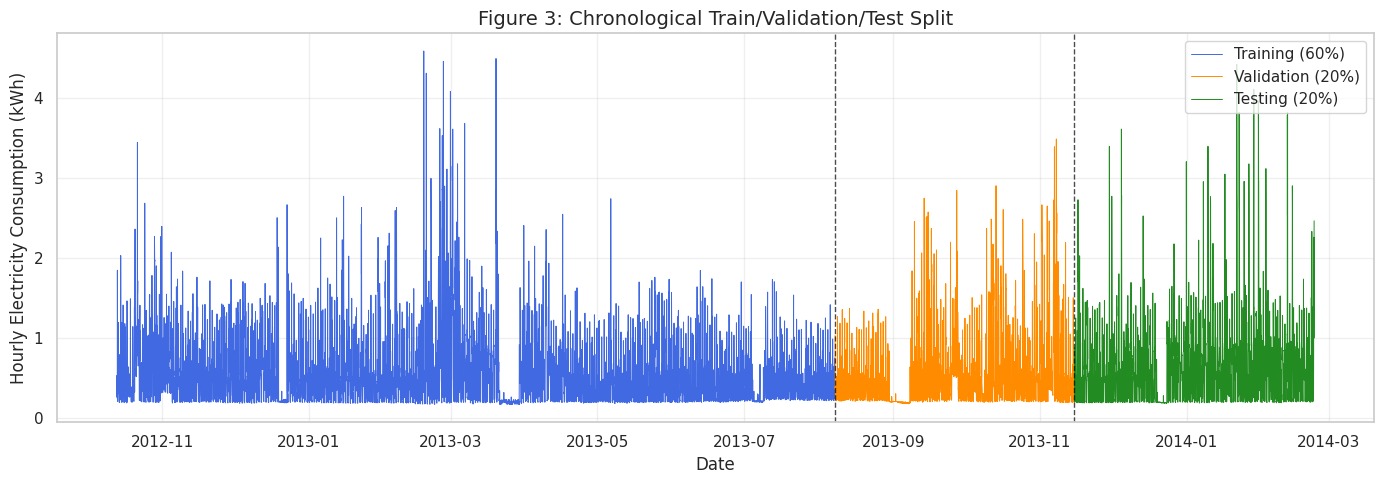

In [19]:
# Step 2B: Visualize chronological train/validation/test split

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))

# Plot each dataset partition
ax.plot(
    train_df.index,
    train_df["consumption_kwh"],
    label="Training (60%)",
    color="royalblue",
    linewidth=0.7
)

ax.plot(
    val_df.index,
    val_df["consumption_kwh"],
    label="Validation (20%)",
    color="darkorange",
    linewidth=0.7
)

ax.plot(
    test_df.index,
    test_df["consumption_kwh"],
    label="Testing (20%)",
    color="forestgreen",
    linewidth=0.7
)

# Mark split boundaries
ax.axvline(
    train_df.index[-1],
    color="black",
    linestyle="--",
    linewidth=1,
    alpha=0.7
)

ax.axvline(
    val_df.index[-1],
    color="black",
    linestyle="--",
    linewidth=1,
    alpha=0.7
)

# Labels and formatting
ax.set_title(
    "Figure 3: Chronological Train/Validation/Test Split",
    fontsize=14
)

ax.set_xlabel("Date")
ax.set_ylabel("Hourly Electricity Consumption (kWh)")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Why are we splitting chronologically?
Unlike regular machine learning datasets, time-series observations have a meaningful order.

We want to simulate forecasting future electricity consumption using only information that would have been available at the time.

For example:
- Training: Older electricity consumption measurements.
- Validation: More recent measurements used to select the best model.
- Testing: The newest measurements used to evaluate performance.
Randomly shuffling observations could introduce information from the future into training.

In [20]:
# Step 3: Missing-value imputation and scaling

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Initialize preprocessing tools
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

# Fit preprocessing tools on training data only
train_imputed = imputer.fit_transform(train_df)

val_imputed = imputer.transform(val_df)
test_imputed = imputer.transform(test_df)

# Fit scaler on imputed training data only
train_scaled = scaler.fit_transform(train_imputed).ravel()

val_scaled = scaler.transform(val_imputed).ravel()
test_scaled = scaler.transform(test_imputed).ravel()

print("Training shape:", train_scaled.shape)
print("Validation shape:", val_scaled.shape)
print("Testing shape:", test_scaled.shape)

print("\nTraining mean:", scaler.mean_[0])
print("Training standard deviation:", scaler.scale_[0])

Training shape: (7171,)
Validation shape: (2390,)
Testing shape: (2391,)

Training mean: 0.48505368859294384
Training standard deviation: 0.41826104062933156


In [21]:
# Step 4A: Create forecasting windows

def make_windows(series, lookback=168, horizon=24):
    X, y = [], []

    for i in range(len(series) - lookback - horizon + 1):
        X.append(series[i:i + lookback])
        y.append(series[i + lookback:i + lookback + horizon])

    return np.array(X), np.array(y)

In [22]:
# Step 4B: Create training, validation, and test windows

# Training windows
X_train, y_train = make_windows(
    train_scaled, LOOKBACK, HORIZON
)

# Validation windows:
# Include historical training observations for context
val_context = np.concatenate([
    train_scaled[-LOOKBACK:],
    val_scaled
])

X_val, y_val = make_windows(
    val_context, LOOKBACK, HORIZON
)

# Testing windows:
# Include historical validation observations for context
test_context = np.concatenate([
    val_scaled[-LOOKBACK:],
    test_scaled
])

X_test, y_test = make_windows(
    test_context, LOOKBACK, HORIZON
)

# Display window shapes
print("Training:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nValidation:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nTesting:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Verify input and output dimensions
assert X_train.shape[1] == LOOKBACK
assert y_train.shape[1] == HORIZON
assert X_val.shape[1] == LOOKBACK
assert y_val.shape[1] == HORIZON
assert X_test.shape[1] == LOOKBACK
assert y_test.shape[1] == HORIZON

Training:
X_train: (6980, 168)
y_train: (6980, 24)

Validation:
X_val: (2367, 168)
y_val: (2367, 24)

Testing:
X_test: (2368, 168)
y_test: (2368, 24)


In [23]:
# Step 5A: Traditional forecasting baselines

# Persistence baseline:
# Repeat the last observed value for all 24 forecast hours
def persistence_baseline(X, horizon=24):
    return np.repeat(
        X[:, -1:],
        horizon,
        axis=1
    )


# Seasonal naive baseline:
# Repeat the previous 24 hours
def seasonal_naive_baseline(X, horizon=24):
    return X[:, -horizon:].copy()


# Generate validation predictions
val_pred_persistence = persistence_baseline(
    X_val, HORIZON
)

val_pred_seasonal = seasonal_naive_baseline(
    X_val, HORIZON
)

# Check prediction shapes
print("Persistence:", val_pred_persistence.shape)
print("Seasonal naive:", val_pred_seasonal.shape)
print("Actual:", y_val.shape)

Persistence: (2367, 24)
Seasonal naive: (2367, 24)
Actual: (2367, 24)


In [24]:
# Step 5B: Evaluation metrics

from sklearn.metrics import mean_absolute_error, mean_squared_error

def inverse_scale(values):
    original_shape = values.shape

    return scaler.inverse_transform(
        values.reshape(-1, 1)
    ).reshape(original_shape)


def evaluate_forecast(y_true, y_pred):

    # Convert back to original kWh units
    actual = inverse_scale(y_true)
    predicted = inverse_scale(y_pred)

    mae = mean_absolute_error(
        actual.ravel(),
        predicted.ravel()
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual.ravel(),
            predicted.ravel()
        )
    )

    # Symmetric Mean Absolute Percentage Error
    denominator = np.abs(actual) + np.abs(predicted)

    smape = 200 * np.mean(
        np.divide(
            np.abs(actual - predicted),
            denominator,
            out=np.zeros_like(actual, dtype=float),
            where=denominator != 0
        )
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "sMAPE (%)": smape
    }


# Evaluate on validation data
persistence_metrics = evaluate_forecast(
    y_val, val_pred_persistence
)

seasonal_metrics = evaluate_forecast(
    y_val, val_pred_seasonal
)

baseline_results = pd.DataFrame([
    {
        "Model": "Persistence",
        **persistence_metrics
    },
    {
        "Model": "Seasonal Naive",
        **seasonal_metrics
    }
])

display(baseline_results)

,Model,MAE,RMSE,sMAPE (%)
0,Persistence,0.336427,0.566006,52.298721
1,Seasonal Naive,0.243710,0.461939,36.135168


In [25]:
# Step 5C: Select the best baseline using validation RMSE

best_baseline = baseline_results.loc[
    baseline_results["RMSE"].idxmin()
]

best_baseline_name = best_baseline["Model"]
best_baseline_rmse = best_baseline["RMSE"]

print("Best baseline:", best_baseline_name)
print("Validation RMSE:", best_baseline_rmse)

Best baseline: Seasonal Naive
Validation RMSE: 0.4619391201624515


# Section III - MLP and Shared Model Registry

**Design rules for this section**
- Every neural model uses the **same windows, horizon, loss (MSE on scaled data), seed, optimiser settings and early-stopping rule**. The shared training loop is `train_model(...)` below and is reused by the CNN grid search.
- Model selection (early stopping, best baseline, best neural model) uses **validation data only**.
- Models are added to `registry` with `register(...)`. The comparison table and the single test evaluation are in **Section V** (end of notebook), so no section needs to edit another.

Helper function to add models to the shared registry:


* name: the label that shows up in the final table, like "CNN".
* predict_fn: a function that takes input windows and returns forecasts
* params, train_time_s: the number of parameters and how long training took, for the table.
* kind: "neural" or "baseline".
* cfg: the settings used, kept for the record.

In [26]:
registry = {}   # name -> dict(kind, predict_fn, params, train_time_s, cfg)

def register(name, predict_fn, params=0, train_time_s=0.0, kind="neural", cfg=None):
    """predict_fn: numpy (N, 168) scaled -> numpy (N, 24) scaled."""
    registry[name] = dict(kind=kind, predict_fn=predict_fn, params=int(params),
                          train_time_s=float(train_time_s), cfg=cfg)
    print(f"Registered: {name} ({kind}, {int(params):,} params)")

MLP training setup:
* Loss: MSE on scaled data
* Optimiser: Adam
* Fixed seed
* Early stopping on validation loss with best-weights restore

In [27]:
import os, time, random
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__, "| seed", SEED)

# Windows as float32 tensors (inputs are already scaled with the training-only scaler)
Xtr, ytr = torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32)
Xva, yva = torch.tensor(X_val,   dtype=torch.float32), torch.tensor(y_val,   dtype=torch.float32)
print("Tensors:", tuple(Xtr.shape), tuple(Xva.shape))

def make_mlp(cfg):
    """Fully connected network: 168 -> hidden layers -> 24."""
    layers, d = [], LOOKBACK
    for h in cfg["hidden"]:
        layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(cfg["dropout"])]
        d = h
    layers.append(nn.Linear(d, HORIZON))
    return nn.Sequential(*layers)

def train_model(model, cfg, verbose=True):
    """Shared training loop for ALL neural models (MLP, CNN, ...).
    MSE loss, Adam, early stopping on VALIDATION loss, best weights restored.
    Returns: model, history, best_epoch (1-based), training time in seconds."""
    set_seed(cfg["seed"])
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    loss_fn = nn.MSELoss()
    g = torch.Generator().manual_seed(cfg["seed"])
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=cfg["batch_size"], shuffle=True, generator=g)
    best_val, best_state, best_epoch, wait = float("inf"), None, 0, 0
    hist = {"train": [], "val": []}
    t0 = time.perf_counter()
    for epoch in range(1, cfg["max_epochs"] + 1):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            opt.step()
        model.eval()
        with torch.no_grad():   # train loss in eval mode (no dropout) so curves are comparable
            tr = loss_fn(model(Xtr.to(device)), ytr.to(device)).item()
            va = loss_fn(model(Xva.to(device)), yva.to(device)).item()
        hist["train"].append(tr); hist["val"].append(va)
        if va < best_val - 1e-6:
            best_val, best_epoch, wait = va, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= cfg["patience"]:
                break
        if verbose and (epoch == 1 or epoch % 10 == 0):
            print(f"epoch {epoch:3d} | train {tr:.4f} | val {va:.4f}")
    model.load_state_dict(best_state)
    return model, hist, best_epoch, time.perf_counter() - t0

Device: cuda | torch 2.11.0+cu130 | seed 42
Tensors: (6980, 168) (2367, 168)


In [28]:
mlp_cfg = dict(hidden=[128, 64], dropout=0.1, lr=1e-3, weight_decay=1e-5,
               batch_size=64, max_epochs=100, patience=10, seed=SEED)

set_seed(SEED)
mlp_model, mlp_hist, mlp_best_epoch, mlp_train_time = train_model(make_mlp(mlp_cfg), mlp_cfg)
mlp_params = sum(p.numel() for p in mlp_model.parameters() if p.requires_grad)
print(f"Best epoch {mlp_best_epoch}/{len(mlp_hist['val'])}, params {mlp_params:,}, train time {mlp_train_time:.1f}s")

epoch   1 | train 0.6723 | val 0.7813
epoch  10 | train 0.4933 | val 0.8007
Best epoch 2/12, params 31,448, train time 3.3s


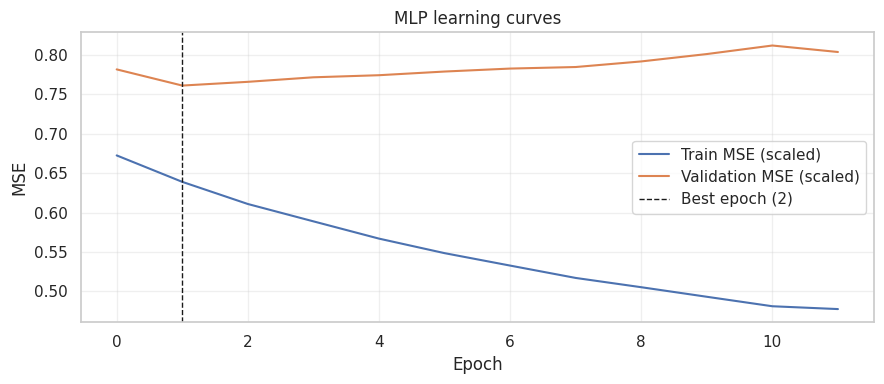

At best epoch: train 0.6388 | val 0.7608 | val/train 1.19
At last epoch: train 0.4777 | val 0.8033
Validation loss rose after the best epoch (overfitting began; best weights restored).


In [29]:
# Learning curves and overfitting check
plt.figure(figsize=(9, 4))
plt.plot(mlp_hist["train"], label="Train MSE (scaled)")
plt.plot(mlp_hist["val"], label="Validation MSE (scaled)")
plt.axvline(mlp_best_epoch - 1, color="k", ls="--", lw=1, label=f"Best epoch ({mlp_best_epoch})")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("MLP learning curves")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

b = mlp_best_epoch - 1
print(f"At best epoch: train {mlp_hist['train'][b]:.4f} | val {mlp_hist['val'][b]:.4f} | val/train {mlp_hist['val'][b]/mlp_hist['train'][b]:.2f}")
print(f"At last epoch: train {mlp_hist['train'][-1]:.4f} | val {mlp_hist['val'][-1]:.4f}")
print("Validation loss rose after the best epoch (overfitting began; best weights restored)."
      if mlp_hist["val"][-1] > 1.05 * mlp_hist["val"][b] else "No clear overfitting after the best epoch.")

Checkpoint, register, and smoke test:

In [30]:
# Save the trained MLP so it survives a restart without retraining
os.makedirs("artifacts", exist_ok=True)
torch.save({"state_dict": mlp_model.state_dict(), "cfg": mlp_cfg}, "artifacts/mlp_baseline.pt")

# Prediction function - numpy (N, 168) scaled -> numpy (N, 24) scaled
def mlp_predict(X, model=mlp_model):
    model.eval() # dropout off
    with torch.no_grad(): # no gradients needed
        return model(torch.tensor(X, dtype=torch.float32).to(device)).cpu().numpy()

# Add the MLP to the shared registry for the comparison table (Section V)
register("MLP", mlp_predict, params=mlp_params, train_time_s=mlp_train_time, cfg=mlp_cfg)

# Check for correct shape (8 windows x 24 hours) and no NaN/inf
_p = mlp_predict(X_val[:8])
assert _p.shape == (8, HORIZON) and np.isfinite(_p).all()
print("Smoke test passed:", _p.shape)

Registered: MLP (neural, 31,448 params)
Smoke test passed: (8, 24)


## MLP hyperparameter tuning (grid search, validation only)

The untuned MLP already beat the tuned CNN on validation, so the MLP is the model that gets tuned (course rule: tune the best model). The search space is fixed before running: hidden sizes, dropout, learning rate and weight decay, with stronger regularisation included because both models start overfitting within the first few epochs. Selection uses validation MSE only; the test set is not touched. The untuned MLP stays registered as `MLP` so the effect of tuning is visible in the final table.

In [31]:
import itertools

mlp_param_grid = {
    "hidden": [[64], [128, 64], [256, 128]],
    "dropout": [0.1, 0.3, 0.5],
    "lr": [1e-3, 3e-4],
    "weight_decay": [1e-5, 1e-3],
}
keys, values = zip(*mlp_param_grid.items())
mlp_grid = [dict(zip(keys, v)) for v in itertools.product(*values)]
print(f"Starting MLP grid search across {len(mlp_grid)} configurations (validation only)...")

mlp_grid_results = []
best_mlp_val = float("inf")

for i, params in enumerate(mlp_grid):
    cfg = {**params, "batch_size": 64, "max_epochs": 100, "patience": 10, "seed": SEED}
    set_seed(SEED)
    model = make_mlp(cfg)
    model, hist, best_ep, t_sec = train_model(model, cfg, verbose=False)
    val_loss = hist["val"][best_ep - 1]
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    mlp_grid_results.append({"trial": i + 1, "config": params, "val_loss": val_loss,
                             "best_epoch": best_ep, "train_time_s": t_sec, "params": n_params})
    if val_loss < best_mlp_val:
        best_mlp_val, best_mlp_cfg, best_mlp_model = val_loss, cfg, model
        best_mlp_hist, best_mlp_epoch, best_mlp_time = hist, best_ep, t_sec

print(f"Best MLP config: {best_mlp_cfg}")
print(f"Best validation MSE: {best_mlp_val:.5f} (scaled RMSE {np.sqrt(best_mlp_val):.5f})")

Starting MLP grid search across 36 configurations (validation only)...
Best MLP config: {'hidden': [256, 128], 'dropout': 0.1, 'lr': 0.0003, 'weight_decay': 0.001, 'batch_size': 64, 'max_epochs': 100, 'patience': 10, 'seed': 42}
Best validation MSE: 0.75733 (scaled RMSE 0.87025)


Table 2: MLP grid search results (36 trials, sorted by validation MSE)


,hidden,dropout,lr,weight_decay,val_MSE,best_epoch,train_time_s,params
0,"[256, 128]",0.1,0.0003,0.00100,0.75733,7,4.0,79256
1,"[256, 128]",0.1,0.0010,0.00100,0.75759,2,2.8,79256
2,"[256, 128]",0.1,0.0010,0.00001,0.75852,2,2.9,79256
3,[64],0.3,0.0010,0.00100,0.75876,13,4.8,12376
4,[64],0.3,0.0003,0.00100,0.75902,19,5.9,12376
5,"[256, 128]",0.1,0.0003,0.00001,0.75966,7,3.9,79256
6,"[256, 128]",0.3,0.0003,0.00100,0.75979,12,5.2,79256
7,[64],0.3,0.0003,0.00001,0.76014,19,6.0,12376
8,"[256, 128]",0.3,0.0003,0.00001,0.76054,9,4.5,79256
9,"[128, 64]",0.1,0.0003,0.00100,0.76072,8,4.2,31448


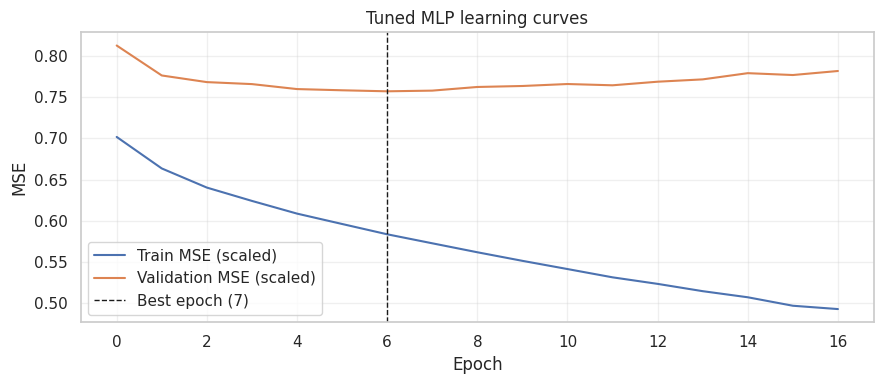

Registered: MLP (tuned) (neural, 79,256 params)
Smoke test passed: (8, 24)


In [32]:
# Table 2: MLP grid results (validation only), then register the tuned MLP
mlp_grid_df = pd.DataFrame([
    {**{k: (str(v) if k == "hidden" else v) for k, v in r["config"].items()},
     "val_MSE": r["val_loss"], "best_epoch": r["best_epoch"],
     "train_time_s": round(r["train_time_s"], 1), "params": r["params"]}
    for r in mlp_grid_results
]).sort_values("val_MSE").reset_index(drop=True)
print(f"Table 2: MLP grid search results ({len(mlp_grid_df)} trials, sorted by validation MSE)")
display(mlp_grid_df.round(5))

plt.figure(figsize=(9, 4))
plt.plot(best_mlp_hist["train"], label="Train MSE (scaled)")
plt.plot(best_mlp_hist["val"], label="Validation MSE (scaled)")
plt.axvline(best_mlp_epoch - 1, color="k", ls="--", lw=1, label=f"Best epoch ({best_mlp_epoch})")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("Tuned MLP learning curves")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

os.makedirs("artifacts", exist_ok=True)
torch.save({"state_dict": best_mlp_model.state_dict(), "cfg": best_mlp_cfg}, "artifacts/mlp_tuned.pt")

def mlp_tuned_predict(X, model=best_mlp_model):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, dtype=torch.float32).to(device)).cpu().numpy()

best_mlp_params = sum(p.numel() for p in best_mlp_model.parameters() if p.requires_grad)
register("MLP (tuned)", mlp_tuned_predict, params=best_mlp_params, train_time_s=best_mlp_time, cfg=best_mlp_cfg)

_p = mlp_tuned_predict(X_val[:8])
assert _p.shape == (8, HORIZON) and np.isfinite(_p).all()
print("Smoke test passed:", _p.shape)

## Section IV — 1D-CNN and Hyperparameter Tuning (Grid Search)

### Architectural & Evaluation Contract:
- **1D Convolutional Architecture:** Convolutions over the temporal lookback axis ($L = 168$) to capture local temporal motifs and seasonal patterns before mapping to horizon $H = 24$.
- **Validation-Only Tuning:** Hyperparameters (kernel size, number of filters, dropout, learning rate) are selected solely using the validation set RMSE/MSE. The test set remains untouched.
- **Fair Protocol:** Uses the identical training protocol, loss function (MSE on scaled targets), seed, and early stopping mechanism defined in Section III.



In [33]:
# 1D Convolutional Neural Network for Time Series Forecasting
import torch
import torch.nn as nn

class ConvNet1D(nn.Module):
    def __init__(self, in_features=168, out_features=24, num_filters=32, kernel_size=3, dropout=0.1):
        super(ConvNet1D, self).__init__()

        padding = kernel_size // 2  # Keep temporal dimension aligned

        self.conv_block = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=num_filters, kernel_size=kernel_size, padding=padding),
            nn.ReLU(),
            nn.BatchNorm1d(num_filters),
            nn.Dropout(dropout),

            nn.Conv1d(in_channels=num_filters, out_channels=num_filters * 2, kernel_size=kernel_size, padding=padding),
            nn.ReLU(),
            nn.BatchNorm1d(num_filters * 2),
            nn.MaxPool1d(kernel_size=2),  # Shape: (batch_size, num_filters*2, in_features // 2)
            nn.Dropout(dropout)
        )

        flattened_dim = (num_filters * 2) * (in_features // 2)

        self.head = nn.Sequential(
            nn.Linear(flattened_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, out_features)
        )

    def forward(self, x):
        # x input is (batch_size, 168)
        if x.dim() == 2:
            x = x.unsqueeze(1)  # Reshape to (batch_size, 1, 168) for Conv1d
        x = self.conv_block(x)
        x = x.flatten(start_dim=1)
        x = self.head(x)
        return x

def make_cnn(cfg):
    """Factory function for CNN instantiation."""
    return ConvNet1D(
        in_features=LOOKBACK,
        out_features=HORIZON,
        num_filters=cfg.get("num_filters", 32),
        kernel_size=cfg.get("kernel_size", 3),
        dropout=cfg.get("dropout", 0.1)
    )

In [34]:
# Grid Search on Validation Data Only
import itertools

# Define Hyperparameter Search Space
cnn_param_grid = {
    "num_filters": [16, 32],
    "kernel_size": [3, 5],
    "lr": [1e-3, 5e-4],
    "dropout": [0.1, 0.2]
}

# Generate all parameter combinations
keys, values = zip(*cnn_param_grid.items())
grid_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

print(f"Starting Grid Search across {len(grid_combinations)} hyperparameter configurations...")

grid_results = []
best_val_loss = float("inf")
best_cnn_cfg = None
best_cnn_model = None
best_cnn_hist = None
best_cnn_epoch = None
best_cnn_time = None

for i, params in enumerate(grid_combinations):
    cfg = {
        "num_filters": params["num_filters"],
        "kernel_size": params["kernel_size"],
        "dropout": params["dropout"],
        "lr": params["lr"],
        "weight_decay": 1e-5,
        "batch_size": 64,
        "max_epochs": 100,
        "patience": 10,
        "seed": SEED
    }

    set_seed(SEED)
    model = make_cnn(cfg)

    # Train with the shared Section III training function (same loss, optimiser, early stopping)
    model, hist, best_ep, t_sec = train_model(model, cfg, verbose=False)  # shared loop from Section III
    val_loss = hist["val"][best_ep - 1]

    param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)

    grid_results.append({
        "trial": i + 1,
        "config": params,
        "val_loss": val_loss,
        "best_epoch": best_ep,
        "train_time_s": t_sec,
        "params": param_count
    })

    print(f"Trial {i+1:02d}/{len(grid_combinations)} | Config: {params} | Val MSE: {val_loss:.5f} | Params: {param_count:,}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_cnn_cfg = cfg
        best_cnn_model = model
        best_cnn_hist = hist
        best_cnn_epoch = best_ep
        best_cnn_time = t_sec

print("\n" + "="*60)
print(f"Best CNN Config: {best_cnn_cfg}")
print(f"Best Validation MSE: {best_val_loss:.5f} (Validation RMSE: {np.sqrt(best_val_loss):.5f})")
print("="*60)

Starting Grid Search across 16 hyperparameter configurations...
Trial 01/16 | Config: {'num_filters': 16, 'kernel_size': 3, 'lr': 0.001, 'dropout': 0.1} | Val MSE: 0.80985 | Params: 175,384
Trial 02/16 | Config: {'num_filters': 16, 'kernel_size': 3, 'lr': 0.001, 'dropout': 0.2} | Val MSE: 0.81440 | Params: 175,384
Trial 03/16 | Config: {'num_filters': 16, 'kernel_size': 3, 'lr': 0.0005, 'dropout': 0.1} | Val MSE: 0.80646 | Params: 175,384
Trial 04/16 | Config: {'num_filters': 16, 'kernel_size': 3, 'lr': 0.0005, 'dropout': 0.2} | Val MSE: 0.80244 | Params: 175,384
Trial 05/16 | Config: {'num_filters': 16, 'kernel_size': 5, 'lr': 0.001, 'dropout': 0.1} | Val MSE: 0.81078 | Params: 176,440
Trial 06/16 | Config: {'num_filters': 16, 'kernel_size': 5, 'lr': 0.001, 'dropout': 0.2} | Val MSE: 0.81634 | Params: 176,440
Trial 07/16 | Config: {'num_filters': 16, 'kernel_size': 5, 'lr': 0.0005, 'dropout': 0.1} | Val MSE: 0.79542 | Params: 176,440
Trial 08/16 | Config: {'num_filters': 16, 'kernel_s

Table 3: CNN grid search results (16 trials, sorted by validation MSE)


,num_filters,kernel_size,lr,dropout,val_MSE,val_RMSE_scaled,best_epoch,train_time_s,params
0,16,5,0.0005,0.2,0.78586,0.88649,2,4.6,176440
1,16,5,0.0005,0.1,0.79542,0.89186,2,4.6,176440
2,16,3,0.0005,0.2,0.80244,0.89579,2,4.5,175384
3,16,3,0.0005,0.1,0.80646,0.89803,1,4.1,175384
4,16,3,0.0010,0.1,0.80985,0.89992,1,6.4,175384
5,16,5,0.0010,0.1,0.81078,0.90043,3,4.9,176440
6,16,3,0.0010,0.2,0.81440,0.90244,1,4.1,175384
7,16,5,0.0010,0.2,0.81634,0.90352,2,4.6,176440
8,32,3,0.0005,0.2,0.82235,0.90683,2,4.7,352216
9,32,3,0.0005,0.1,0.82476,0.90816,1,4.3,352216


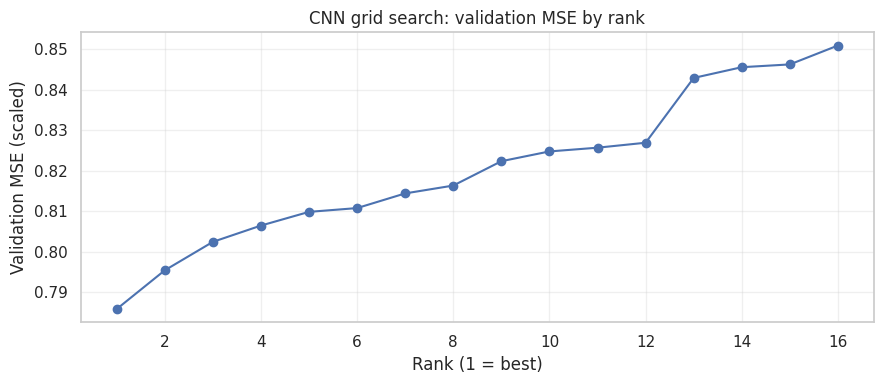

In [35]:
# Grid search results (validation only): table sorted by validation MSE + plot
grid_df = pd.DataFrame([
    {**r["config"], "val_MSE": r["val_loss"], "val_RMSE_scaled": np.sqrt(r["val_loss"]),
     "best_epoch": r["best_epoch"], "train_time_s": round(r["train_time_s"], 1), "params": r["params"]}
    for r in grid_results
]).sort_values("val_MSE").reset_index(drop=True)
print("Table 3: CNN grid search results (16 trials, sorted by validation MSE)")
display(grid_df.round(5))

plt.figure(figsize=(9, 4))
plt.plot(range(1, len(grid_df) + 1), grid_df["val_MSE"].values, marker="o")
plt.xlabel("Rank (1 = best)"); plt.ylabel("Validation MSE (scaled)")
plt.title("CNN grid search: validation MSE by rank")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

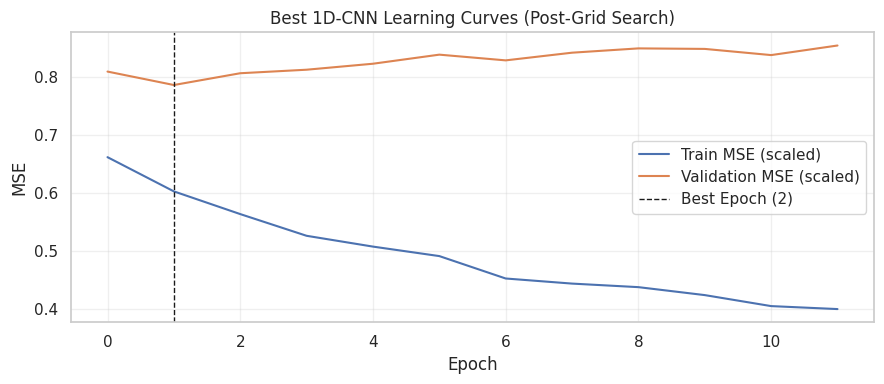

At best epoch: train 0.6030 | val 0.7859 | val/train ratio: 1.30
At last epoch: train 0.4007 | val 0.8538
Validation loss rose after best epoch (overfitting began; best weights restored).


In [36]:
# Plot learning curves for the winning CNN model
plt.figure(figsize=(9, 4))
plt.plot(best_cnn_hist["train"], label="Train MSE (scaled)")
plt.plot(best_cnn_hist["val"], label="Validation MSE (scaled)")
plt.axvline(best_cnn_epoch - 1, color="k", ls="--", lw=1, label=f"Best Epoch ({best_cnn_epoch})")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Best 1D-CNN Learning Curves (Post-Grid Search)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

b = best_cnn_epoch - 1
print(f"At best epoch: train {best_cnn_hist['train'][b]:.4f} | val {best_cnn_hist['val'][b]:.4f} | val/train ratio: {best_cnn_hist['val'][b]/best_cnn_hist['train'][b]:.2f}")
print(f"At last epoch: train {best_cnn_hist['train'][-1]:.4f} | val {best_cnn_hist['val'][-1]:.4f}")
print("Validation loss rose after best epoch (overfitting began; best weights restored)."
      if best_cnn_hist["val"][-1] > 1.05 * best_cnn_hist["val"][b] else "No clear overfitting after best epoch.")

In [37]:
import os

# Save trained CNN checkpoint to disk
os.makedirs("artifacts", exist_ok=True)
torch.save({"state_dict": best_cnn_model.state_dict(), "cfg": best_cnn_cfg}, "artifacts/cnn_best.pt")

# Define predict function
def cnn_predict(X, model=best_cnn_model):
    model.eval()
    with torch.no_grad():
        x_tensor = torch.tensor(X, dtype=torch.float32).to(device)
        return model(x_tensor).cpu().numpy()

# Add Best CNN to shared comparison registry
best_cnn_params = sum(p.numel() for p in best_cnn_model.parameters() if p.requires_grad)
register("CNN", cnn_predict, params=best_cnn_params, train_time_s=best_cnn_time, cfg=best_cnn_cfg)

# Check basics work (Smoke Test)
_p = cnn_predict(X_val[:8])
assert _p.shape == (8, HORIZON) and np.isfinite(_p).all(), "CNN prediction shape or values invalid!"
print("Smoke test passed:", _p.shape)

Registered: CNN (neural, 176,440 params)
Smoke test passed: (8, 24)


### Seed-noise check (validation only)

Early stopping picks epoch 1-3 for most trials, and differences between grid configurations are small. To judge whether a ranking is meaningful, each chosen configuration is retrained with 3 seeds and the spread in validation MSE is compared with the gap between the top configurations in each grid.

In [38]:
def seed_noise(make_fn, cfg, seeds=(42, 43, 44)):
    vals = []
    for s in seeds:
        c = {**cfg, "seed": s}
        set_seed(s)
        m, h, be, _ = train_model(make_fn(c), c, verbose=False)
        vals.append(h["val"][be - 1])
    return float(np.mean(vals)), float(np.std(vals))

rows = []
for label, fn, cfg in [("MLP (untuned)", make_mlp, mlp_cfg),
                       ("MLP (tuned)", make_mlp, best_mlp_cfg),
                       ("CNN (tuned)", make_cnn, best_cnn_cfg)]:
    mean_v, std_v = seed_noise(fn, cfg)
    rows.append({"Model": label, "Val MSE mean (3 seeds)": mean_v, "Val MSE std": std_v})
noise_df = pd.DataFrame(rows)
print("Table 4: Seed noise in validation MSE (scaled)")
display(noise_df.round(4))

mlp_sorted = sorted(r["val_loss"] for r in mlp_grid_results)
cnn_sorted = sorted(r["val_loss"] for r in grid_results)
max_std = noise_df["Val MSE std"].max()
print(f"MLP grid: gap between top-2 configs = {mlp_sorted[1]-mlp_sorted[0]:.4f} | CNN grid: gap = {cnn_sorted[1]-cnn_sorted[0]:.4f} | largest seed std = {max_std:.4f}")
print("Gaps smaller than the seed std mean the grid ranking is within noise; do not over-claim the winning configuration."
      if min(mlp_sorted[1]-mlp_sorted[0], cnn_sorted[1]-cnn_sorted[0]) < max_std else
      "Top-config gaps exceed the seed std, so the grid ranking is more than noise.")

Table 4: Seed noise in validation MSE (scaled)


,Model,Val MSE mean (3 seeds),Val MSE std
0,MLP (untuned),0.7613,0.0009
1,MLP (tuned),0.7563,0.0013
2,CNN (tuned),0.7974,0.0081


MLP grid: gap between top-2 configs = 0.0003 | CNN grid: gap = 0.0096 | largest seed std = 0.0081
Gaps smaller than the seed std mean the grid ranking is within noise; do not over-claim the winning configuration.


# Section V - Model Comparison, Final Test, Conclusion and Risk

This section only reads `registry`; it trains nothing. Baselines are picked up automatically: any function in the notebook named `*_baseline` with signature `fn(X, horizon)` is registered. Run this section **last**, after the MLP and CNN are registered.

In [39]:
import inspect

# Auto-register baselines by naming convention
for _n, _f in list(globals().items()):
    if _n.endswith("_baseline") and inspect.isfunction(_f):
        label = _n[:-len("_baseline")].replace("_", " ").title()
        if label in registry:
            continue
        try:
            _out = _f(X_val[:2], HORIZON)
            assert _out.shape == (2, HORIZON)
        except Exception as e:
            print("Skipped", _n, "-", e)
            continue
        register(label, (lambda X, f=_f: f(X, HORIZON)), kind="baseline")

# Validation metrics + inference time, computed the same way for every model
for name, e in registry.items():
    if "val" in e:
        continue
    t0 = time.perf_counter()
    pred = e["predict_fn"](X_val)
    e["infer_time_s"] = time.perf_counter() - t0
    assert pred.shape == y_val.shape, f"{name}: predict_fn returned {pred.shape}, expected {y_val.shape}"
    e["val"] = evaluate_forecast(y_val, pred)

def best_baseline_by_val():
    cands = {k: v for k, v in registry.items() if v["kind"] == "baseline"}
    return min(cands, key=lambda k: cands[k]["val"]["RMSE"])

print("Models:", list(registry))
print("Best baseline on validation RMSE:", best_baseline_by_val())

Registered: Persistence (baseline, 0 params)
Registered: Seasonal Naive (baseline, 0 params)
Models: ['MLP', 'MLP (tuned)', 'CNN', 'Persistence', 'Seasonal Naive']
Best baseline on validation RMSE: Seasonal Naive


In [40]:
def build_table(split="val"):
    base_name = best_baseline_by_val()
    base = registry[base_name][split]
    rows = []
    for name, e in registry.items():
        m = e[split]
        rows.append({
            "Model": name,
            "Params": e["params"],
            "Train time (s)": round(e["train_time_s"], 1),
            "Inference time (s)": round(e["infer_time_s"], 4),
            "MAE (kWh)": round(m["MAE"], 4),
            "RMSE (kWh)": round(m["RMSE"], 4),
            "sMAPE (%)": round(m["sMAPE (%)"], 2),
            f"MAE impr. vs {base_name} (%)": round(100 * (base["MAE"] - m["MAE"]) / base["MAE"], 1),
            f"RMSE impr. vs {base_name} (%)": round(100 * (base["RMSE"] - m["RMSE"]) / base["RMSE"], 1),
        })
    return pd.DataFrame(rows).sort_values("RMSE (kWh)").reset_index(drop=True)

print("Table 1a: Validation results (use this table for model selection)")
display(build_table("val"))

Table 1a: Validation results (use this table for model selection)


,Model,Params,Train time (s),Inference time (s),MAE (kWh),RMSE (kWh),sMAPE (%),MAE impr. vs Seasonal Naive (%),RMSE impr. vs Seasonal Naive (%)
0,MLP (tuned),79256,4.0,0.0014,0.2253,0.3640,40.78,7.6,21.2
1,MLP,31448,3.3,0.0022,0.2256,0.3648,41.03,7.4,21.0
2,CNN,176440,4.6,0.0066,0.2349,0.3708,43.66,3.6,19.7
3,Seasonal Naive,0,0.0,0.0001,0.2437,0.4619,36.14,0.0,0.0
4,Persistence,0,0.0,0.0001,0.3364,0.5660,52.30,-38.0,-22.5


## Final test comparison (run once)

Run only after every model is registered and the final model is chosen from Table 1a. Do not change models or settings after viewing Table 1b.

In [41]:
TEST_DONE = globals().get("TEST_DONE", False)

if not TEST_DONE:
    for name, e in registry.items():
        e["test"] = evaluate_forecast(y_test, e["predict_fn"](X_test))
    TEST_DONE = True

print("Table 1b: Final test results (baseline fixed from validation:", best_baseline_by_val() + ")")
display(build_table("test"))

Table 1b: Final test results (baseline fixed from validation: Seasonal Naive)


,Model,Params,Train time (s),Inference time (s),MAE (kWh),RMSE (kWh),sMAPE (%),MAE impr. vs Seasonal Naive (%),RMSE impr. vs Seasonal Naive (%)
0,MLP (tuned),79256,4.0,0.0014,0.2436,0.4019,40.45,10.2,21.7
1,MLP,31448,3.3,0.0022,0.2430,0.4034,40.78,10.4,21.4
2,CNN,176440,4.6,0.0066,0.2560,0.4094,44.15,5.6,20.2
3,Seasonal Naive,0,0.0,0.0001,0.2712,0.5130,37.30,0.0,0.0
4,Persistence,0,0.0,0.0001,0.4534,0.7036,66.60,-67.2,-37.2


In [42]:
# Run AFTER Table 1b. Does the seasonal-shift risk show up?
period_stats = pd.DataFrame({
    "Period": ["Train", "Validation", "Test"],
    "Mean kWh/h": [train_df["consumption_kwh"].mean(), val_df["consumption_kwh"].mean(), test_df["consumption_kwh"].mean()],
    "Std kWh/h": [train_df["consumption_kwh"].std(), val_df["consumption_kwh"].std(), test_df["consumption_kwh"].std()],
}).round(3)
display(period_stats)

shift = pd.DataFrame({
    "Model": list(registry),
    "Val RMSE": [registry[k]["val"]["RMSE"] for k in registry],
    "Test RMSE": [registry[k]["test"]["RMSE"] for k in registry],
})
shift["Test/Val RMSE"] = (shift["Test RMSE"] / shift["Val RMSE"]).round(2)
display(shift.round(4))

,Period,Mean kWh/h,Std kWh/h
0,Train,0.485,0.418
1,Validation,0.482,0.437
2,Test,0.583,0.515


,Model,Val RMSE,Test RMSE,Test/Val RMSE
0,MLP,0.3648,0.4034,1.11
1,MLP (tuned),0.3640,0.4019,1.10
2,CNN,0.3708,0.4094,1.10
3,Persistence,0.5660,0.7036,1.24
4,Seasonal Naive,0.4619,0.5130,1.11


# Conclusion and unresolved risk

> **Update before the demo:** the numbers below come from the run *before* the MLP was tuned. After rerunning, re-check them against Table 1b (the tuned MLP may change the best model and the margins).


**Best model:** The MLP had the lowest test RMSE (0.4034 kWh), 21.4% better than the best baseline, Seasonal Naive (0.5130), and 10.4% better in MAE. It is also cheaper than the CNN (31,448 vs 176,440 parameters).

**Neural vs. baseline:** Both neural models beat Seasonal Naive on RMSE and MAE, but not on sMAPE (MLP 40.78% vs 37.30%), so the gain is in squared and absolute error, not relative error at low-consumption hours.

**Validation vs. test:** Rankings were identical, and the MLP’s improvement over the baseline was stable (21.0% to 21.4%). All models’ errors rose about 10% on test, including the untrained baseline, which points to a harder winter period (mean consumption about 20% higher) rather than a model-specific failure.

**Unresolved risk:** The validation period (7 Aug - 15 Nov 2013, late summer to autumn) and the test period (15 Nov 2013 - 22 Feb 2014, winter including Christmas/New Year) cover different seasons. Training contains only one winter (Dec 2012 - Feb 2013), and the scaler is fit on a training mean of about 0.49 kWh/h. Early stopping and grid search are tuned on autumn data, so they may not transfer to winter demand. Also, only one household (T1) is modelled so far, so results may not generalise to the aggregate (mean per household) series.